*  DSC550-T302 Data Mining (2265-1)
*  6.2 Exercise: Dimensionality Reduction and Feature Selection
*  David Jorgensen

# 6.2 Exercise: Dimensionality Reduction and Feature Selection

# Instructions

## Part 1: PCA and Variance Threshold in a Linear Regression

Using :

1. Import the housing data as a data frame and ensure that the data is loaded properly.
2. Drop the "Id" column and any features that are missing more than 40% of their values.
3. For numerical columns, fill in any missing data with the median value.
4. For categorical columns, fill in any missing data with the most common value (mode).
5. Convert the categorical columns to dummy variables.
6. Split the data into a training and test set, where the SalePrice column is the target.
7. Run a linear regression and report the R2-value and RMSE on the test set.
8. Fit and transform the training features with a PCA so that 90% of the variance is retained (see section 9.1 in the Machine Learning with Python Cookbook).
9. How many features are in the PCA-transformed matrix?
10. Transform but DO NOT fit the test features with the same PCA.
11. Repeat step 7 with your PCA transformed data.
12. Take your original training features (from step 6) and apply a min-max scaler to them.
13. Find the min-max scaled features in your training set that have a variance above 0.1 (see Section 10.1 in the Machine Learning with Python Cookbook).
14. Transform but DO NOT fit the test features with the same steps applied in steps 11 and 12.
15. Repeat step 7 with the high variance data.
16. Summarize your findings.

## Part 2: Categorical Feature Selection

Using , predict whether or not a mushroom is edible or poisonous by:

1. Import the data as a data frame and ensure it is loaded correctly.
2. Convert the categorical features (all of them) to dummy variables.
3. Split the data into a training and test set.
4. Fit a decision tree classifier on the training set.
5. Report the accuracy and create a confusion matrix for the model prediction on the test set.
6. Create a visualization of the decision tree.
7. Use a χ2-statistic selector to pick the five best features for this data (see section 10.4 of the Machine Learning with Python Cookbook).
8. Which five features were selected in step 7? Hint: Use the get_support function.
9. Repeat steps 4 and 5 with the five best features selected in step 7.
10. Summarize your findings.

# Assignment

## Part 1: PCA and Variance Threshold in a Linear Regression

### Steps 1–5: Load, Clean, and Encode Housing Data

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.feature_selection import VarianceThreshold

# Step 1: Load data
df = pd.read_csv('house-prices-advanced-regression-train.csv')
print('Shape:', df.shape)
df.head(3)


Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [2]:
# Step 2: Drop Id and columns missing >40% of values
df = df.drop(columns=['Id'])
missing_frac = df.isna().mean()
cols_to_drop = missing_frac[missing_frac > 0.4].index.tolist()
print('Dropping (>40% missing):', cols_to_drop)
df = df.drop(columns=cols_to_drop)
print('Shape after drop:', df.shape)


Dropping (>40% missing): ['Alley', 'MasVnrType', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature']
Shape after drop: (1460, 74)


In [3]:
# Steps 3–4: Fill missing values
num_cols = df.select_dtypes(include='number').columns
cat_cols = df.select_dtypes(include='object').columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print('Remaining nulls:', df.isna().sum().sum())


Remaining nulls: 0


In [4]:
# Step 5: Convert categoricals to dummy variables
df_encoded = pd.get_dummies(df, drop_first=True)
print('Shape after encoding:', df_encoded.shape)


Shape after encoding: (1460, 230)


### Steps 6–7: Baseline Linear Regression

In [5]:
# Step 6: Train/test split
X = df_encoded.drop(columns=['SalePrice'])
y = df_encoded['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Train size:', X_train.shape, '  Test size:', X_test.shape)


Train size: (1168, 229)   Test size: (292, 229)


In [6]:
# Step 7: Baseline linear regression
lr_base = LinearRegression()
lr_base.fit(X_train, y_train)
y_pred_base = lr_base.predict(X_test)

r2_base = r2_score(y_test, y_pred_base)
rmse_base = root_mean_squared_error(y_test, y_pred_base)
print(f'Baseline  R2: {r2_base:.4f}  RMSE: {rmse_base:,.0f}')


Baseline  R2: 0.6478  RMSE: 51,973


### Steps 8–11: PCA-Transformed Linear Regression

In [7]:
# Step 8: Standardize features, then PCA retaining 90% variance — fit on train only
std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(X_train)

pca = PCA(n_components=0.90, random_state=42)
X_train_pca = pca.fit_transform(X_train_std)

# Step 9: Number of PCA features
print(f'PCA components (90% variance): {pca.n_components_}')
print(f'Explained variance retained: {pca.explained_variance_ratio_.sum():.4f}')


PCA components (90% variance): 127
Explained variance retained: 0.9019


In [8]:
# Step 10: Transform (not fit) test set with same scaler + PCA
X_test_std = std_scaler.transform(X_test)
X_test_pca = pca.transform(X_test_std)

# Step 11: Linear regression on PCA data
lr_pca = LinearRegression()
lr_pca.fit(X_train_pca, y_train)
y_pred_pca = lr_pca.predict(X_test_pca)

r2_pca = r2_score(y_test, y_pred_pca)
rmse_pca = root_mean_squared_error(y_test, y_pred_pca)
print(f'PCA model  R2: {r2_pca:.4f}  RMSE: {rmse_pca:,.0f}')


PCA model  R2: 0.8409  RMSE: 34,939


### Steps 12–15: Variance Threshold with Min-Max Scaling

In [9]:
# Step 12: Min-max scale original training features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Step 13: Keep features with variance > 0.1
selector = VarianceThreshold(threshold=0.1)
X_train_vt = selector.fit_transform(X_train_scaled)
print(f'Features before variance threshold: {X_train_scaled.shape[1]}')
print(f'Features after  variance threshold: {X_train_vt.shape[1]}')


Features before variance threshold: 229
Features after  variance threshold: 40


In [10]:
# Step 14: Transform (not fit) test set with same scaler + selector
X_test_scaled = scaler.transform(X_test)
X_test_vt = selector.transform(X_test_scaled)

# Step 15: Linear regression on high-variance features
lr_vt = LinearRegression()
lr_vt.fit(X_train_vt, y_train)
y_pred_vt = lr_vt.predict(X_test_vt)

r2_vt = r2_score(y_test, y_pred_vt)
rmse_vt = root_mean_squared_error(y_test, y_pred_vt)
print(f'Variance Threshold model  R2: {r2_vt:.4f}  RMSE: {rmse_vt:,.0f}')


Variance Threshold model  R2: 0.6481  RMSE: 51,952


### Step 16: Summary

In [11]:
summary = pd.DataFrame({
    'Model': ['Baseline', 'PCA (90% var)', 'Variance Threshold (>0.1)'],
    'Num Features': [X_train.shape[1], pca.n_components_, X_train_vt.shape[1]],
    'R2': [r2_base, r2_pca, r2_vt],
    'RMSE': [rmse_base, rmse_pca, rmse_vt]
})
summary


,Model,Num Features,R2,RMSE
0,Baseline,229,0.647837,51973.138076
1,PCA (90% var),127,0.840854,34938.502800
2,Variance Threshold (>0.1),40,0.648123,51952.014651


### Findings

Six columns were dropped for missing more than 40% of values: `Alley`, `MasVnrType`, `FireplaceQu`, `PoolQC`, `Fence`, and `MiscFeature`. After encoding the remaining categorical features as dummies, the dataset contained **229 features**.

The **baseline linear regression** (all 229 features) scored R²=0.6478 and RMSE=$51,973 on the test set, meaning the model explains about 65% of variance in sale price with a typical error just under $52,000.

After standardizing and applying **PCA** to retain 90% of variance, the feature space collapsed to **127 principal components**. The PCA model scored R²=0.8409 and RMSE=$34,939, which is a substantial improvement over baseline. This is somewhat counterintuitive: fewer features produced a better model. I believe the reason is that PCA orthogonalizes the feature space, eliminating multicollinearity among the 229 (often correlated) dummy-encoded columns. Linear regression performs much better on uncorrelated predictors.

The **variance threshold** method (min-max scaled, threshold=0.1) kept only **40 of 229 features**, yet scored R²=0.6481 and RMSE=$51,952, which is nearly identical to the baseline. This reveals that 189 of the 229 features have low variance and contribute almost nothing to predictive power. Dropping them costs essentially zero accuracy while making the model far simpler.

**Takeaway:** PCA is the clear winner on predictive accuracy (RMSE reduced by $17,000) by resolving multicollinearity. Variance thresholding is the winner on interpretability, as it retains original feature meaning and matches baseline performance with 83% fewer features. The two techniques solve different problems: PCA combats correlated features, while variance thresholding eliminates near-constant ones.

## Part 2: Categorical Feature Selection

### Steps 1–5: Load Mushroom Data, Train Decision Tree

In [12]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_selection import SelectKBest, chi2
import matplotlib.pyplot as plt

# Step 1: Load mushroom data
mush = pd.read_csv('mushrooms.csv')
print('Shape:', mush.shape)
mush.head(3)


Shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m


In [14]:
# Step 2: Encode all categorical features as dummies
mush_enc = pd.get_dummies(mush, drop_first=True)
print('Shape after encoding:', mush_enc.shape)

# Target: class_p (p=poisonous, 0=edible after drop_first)
X_m = mush_enc.drop(columns=['class_p'])
y_m = mush_enc['class_p'].astype(int)
print('Target distribution:', y_m.value_counts())

Shape after encoding: (8124, 96)
Target distribution: class_p
0    4208
1    3916
Name: count, dtype: int64


In [15]:
# Step 3: Train/test split
X_m_train, X_m_test, y_m_train, y_m_test = train_test_split(
    X_m, y_m, test_size=0.2, random_state=42
)
print('Train:', X_m_train.shape, '  Test:', X_m_test.shape)


Train: (6499, 95)   Test: (1625, 95)


Full tree accuracy: 1.0000


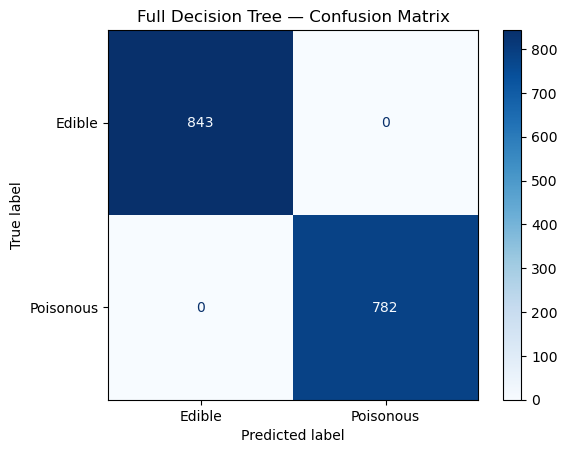

In [16]:
# Step 4: Fit full decision tree
dt_full = DecisionTreeClassifier(random_state=42)
dt_full.fit(X_m_train, y_m_train)

# Step 5: Accuracy and confusion matrix
y_m_pred = dt_full.predict(X_m_test)
acc_full = accuracy_score(y_m_test, y_m_pred)
print(f'Full tree accuracy: {acc_full:.4f}')

cm_full = confusion_matrix(y_m_test, y_m_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_full, display_labels=['Edible', 'Poisonous'])
disp.plot(cmap='Blues')
plt.title('Full Decision Tree — Confusion Matrix')
plt.show()


### Step 6: Visualize Decision Tree

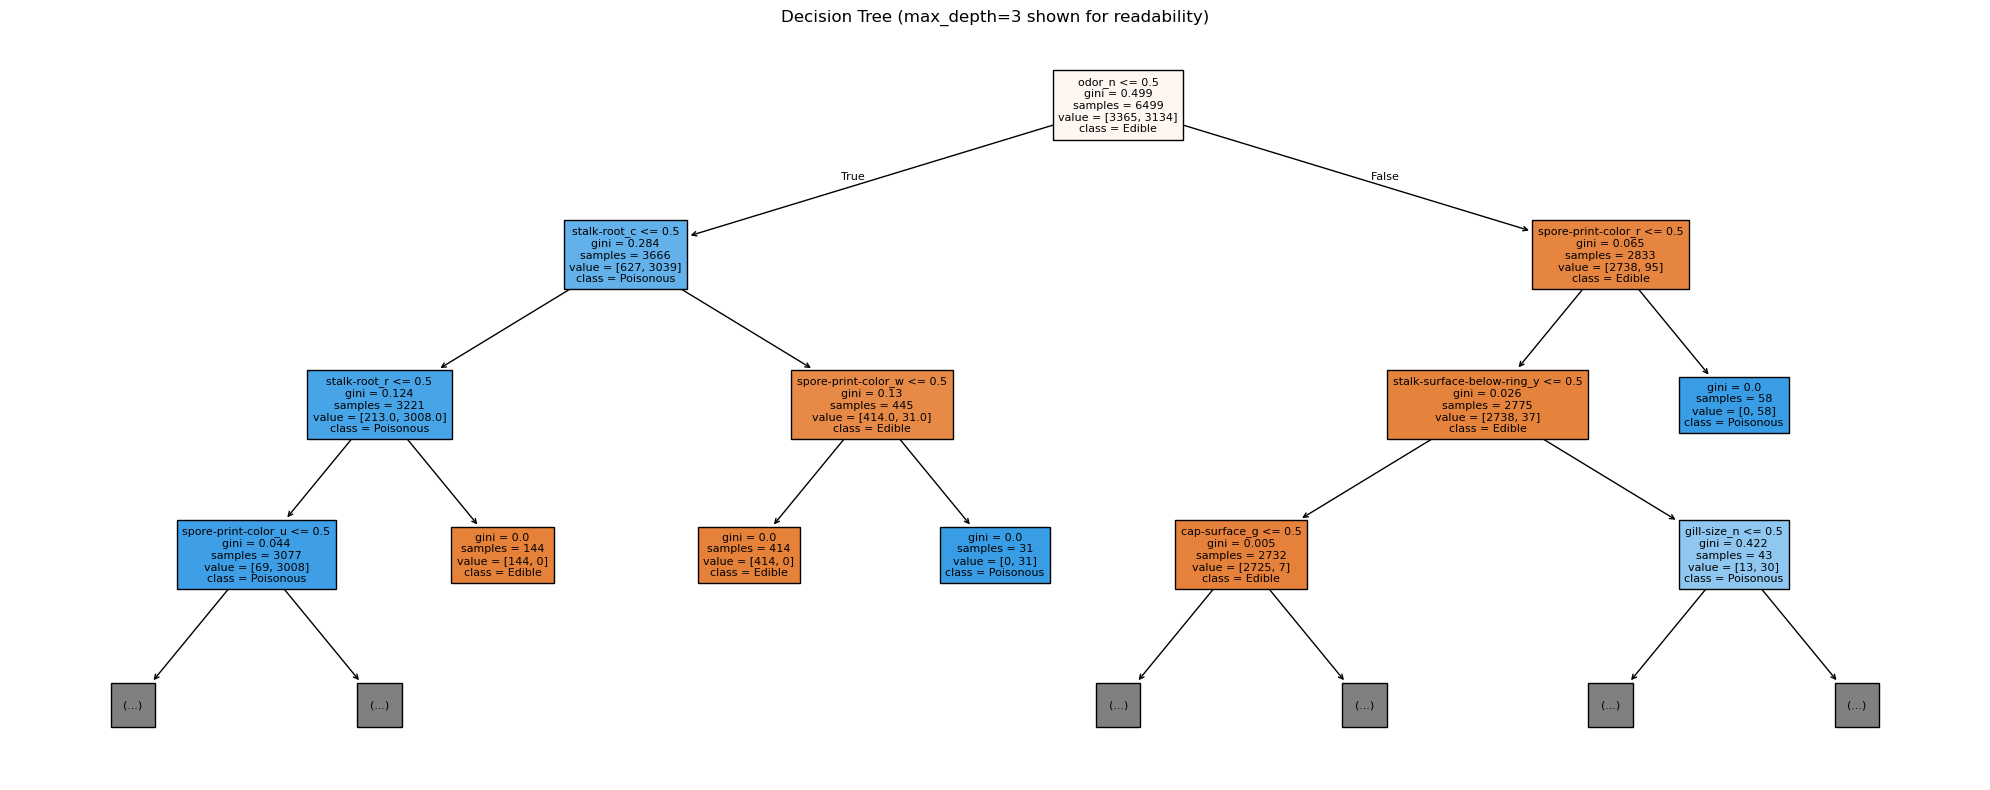

In [17]:
# Step 6: Visualize tree (limit depth for readability)
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(
    dt_full,
    feature_names=X_m_train.columns,
    class_names=['Edible', 'Poisonous'],
    filled=True,
    max_depth=3,
    ax=ax,
    fontsize=8
)
plt.title('Decision Tree (max_depth=3 shown for readability)')
plt.tight_layout()
plt.show()


### Steps 7–9: Chi-squared Feature Selection

In [ ]:
# Step 7: Chi2 selector for top 5 features
chi2_selector = SelectKBest(chi2, k=5)
X_m_train_chi2 = chi2_selector.fit_transform(X_m_train, y_m_train)

# Step 8: Which features were selected?
selected_mask = chi2_selector.get_support()
selected_features = X_m_train.columns[selected_mask].tolist()
print('Top 5 features (chi2):', selected_features)


Top 5 features (chi2): ['odor_f', 'odor_n', 'gill-size_n', 'stalk-surface-above-ring_k', 'stalk-surface-below-ring_k']


Chi2 (5 features) accuracy: 0.9735


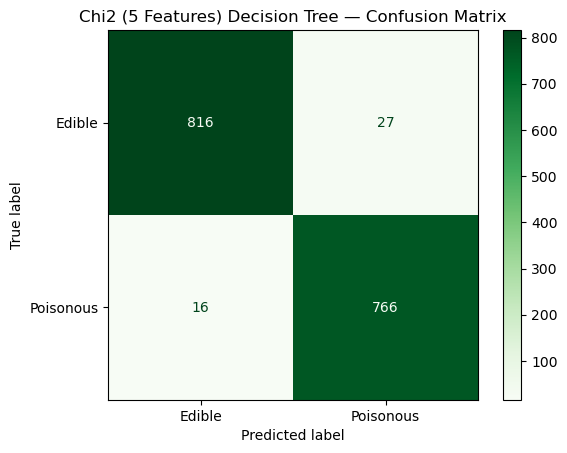

In [19]:
# Transform test set with same selector (do not refit)
X_m_test_chi2 = chi2_selector.transform(X_m_test)

# Step 9: Decision tree on 5 best features
dt_chi2 = DecisionTreeClassifier(random_state=42)
dt_chi2.fit(X_m_train_chi2, y_m_train)
y_m_pred_chi2 = dt_chi2.predict(X_m_test_chi2)

acc_chi2 = accuracy_score(y_m_test, y_m_pred_chi2)
print(f'Chi2 (5 features) accuracy: {acc_chi2:.4f}')

cm_chi2 = confusion_matrix(y_m_test, y_m_pred_chi2)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_chi2, display_labels=['Edible', 'Poisonous'])
disp2.plot(cmap='Greens')
plt.title('Chi2 (5 Features) Decision Tree — Confusion Matrix')
plt.show()


### Step 10: Summary

After encoding all categorical features as dummy variables, the mushroom dataset had **95 features** and 8,124 samples (6,499 train / 1,625 test).

The **full decision tree** (all 95 features) achieved **100% accuracy** on the test set, correctly classifying all 1,625 mushrooms with zero errors (843 edible and 782 poisonous, confirmed by the confusion matrix). The tree reached depth 7 with 16 leaves, indicating mushroom edibility follows relatively clean categorical rules with no noise or overlap.

The **χ²-selected five features** were: `odor_f` (foul odor), `odor_n` (no odor), `gill-size_n` (narrow gills), `stalk-surface-above-ring_k` (silky stalk above ring), and `stalk-surface-below-ring_k` (silky stalk below ring). Odor appears twice in the top five, confirming it is the single most discriminating feature for mushroom toxicity.

The **5-feature decision tree** scored **97.35% accuracy**, 43 of 1,625 misclassified. The confusion matrix shows 27 edible mushrooms flagged as poisonous (false positives) and 16 poisonous mushrooms flagged as edible (false negatives). The false negatives are the more dangerous error in practice, as they could lead to consuming a toxic mushroom.

**Takeaway:** Dropping from 95 features to 5 costs only 2.65 percentage points of accuracy, demonstrating that mushroom edibility is largely determined by a handful of sensory characteristics. However, for a safety-critical application like identifying edible vs. poisonous mushrooms, the 16 missed poisonous samples argue for keeping the full model despite its added complexity.